In [1]:
# Cấu hình thư viện và môi trường làm việc
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, load_digits, make_classification
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Cấu hình hiển thị đồ họa
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Kiểm tra đường dẫn dữ liệu
data_dir = "data" if os.path.exists("data") else "."
path_sv = os.path.join(data_dir, "sinh_vien.csv")
path_sv_mr = os.path.join(data_dir, "sinh_vien_mo_rong.csv")
path_moon = os.path.join(data_dir, "hai_vang_trang.csv")

print("Nạp thư viện thành công!")
print(f"File sinh_vien         : {path_sv} (tồn tại: {os.path.exists(path_sv)})")
print(f"File sinh_vien_mo_rong : {path_sv_mr} (tồn tại: {os.path.exists(path_sv_mr)})")
print(f"File hai_vang_trang    : {path_moon} (tồn tại: {os.path.exists(path_moon)})")


Nạp thư viện thành công!
File sinh_vien         : data\sinh_vien.csv (tồn tại: True)
File sinh_vien_mo_rong : data\sinh_vien_mo_rong.csv (tồn tại: True)
File hai_vang_trang    : data\hai_vang_trang.csv (tồn tại: True)


---
## 1. ĐƯỜNG CÓ LỀ RỘNG NHẤT VÀ VECTƠ HỖ TRỢ (g1_le_rong_nhat.py)

### 1.1. Ý tưởng toán học
Khi hai lớp dữ liệu tách biệt hoàn toàn, có vô số đường thẳng phân chia được chúng. SVM chọn ra **đường ranh giới nằm chính giữa con đường rộng nhất** có thể kẻ được giữa hai lớp.

- Đường ranh giới quyết định:
  $$f(x) = w_1 x_1 + w_2 x_2 + b = 0$$
- Dự đoán lớp:
  $$\hat{y} = 1 \text{ khi } f(x) > 0, \quad \hat{y} = 0 \text{ khi } f(x) < 0$$
- Hai mép lề (Margin Boundaries) là hai đường thẳng $f(x) = 1$ và $f(x) = -1$.
- Độ rộng của lề (Margin Width):
  $$\text{lề} = \frac{2}{\|w\|} = \frac{2}{\sqrt{w_1^2 + w_2^2}}$$
- Các điểm nằm đúng trên hai mép lề ($f(x) = \pm 1$) được gọi là **vectơ hỗ trợ (Support Vectors)**. Chỉ có các điểm này mới quyết định vị trí của đường ranh giới!


w1 = -0.831, w2 = -0.355, b = 4.820
Do rong cua le = 2 / 0.9039 = 2.2126

So vecto ho tro: 3
 diem 18: x1 = 5.20, x2 = 4.22, lop 0, f(x) = -1.000
 diem 10: x1 = 2.88, x2 = 4.02, lop 1, f(x) = +1.000
 diem 13: x1 = 3.59, x2 = 2.36, lop 1, f(x) = +1.000

|f(x)| nho nhat cua cac diem khac: 1.059

Hoc lai chi voi vecto ho tro:
 w1 = -0.831, w2 = -0.355, b = 4.821

Diem (3.0, 3.0): f(x) = +1.262, doan lop 1
Diem (5.0, 4.5): f(x) = -0.933, doan lop 0


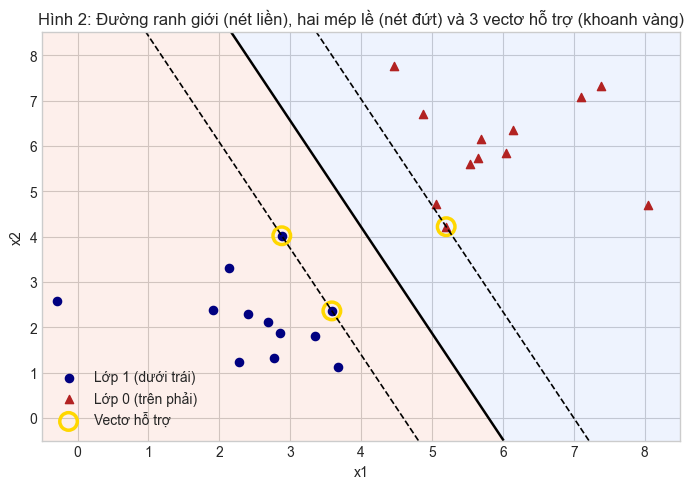

In [2]:
# Bước 1: Tìm đường có lề rộng nhất và các vectơ hỗ trợ trên 24 điểm mô phỏng

# 1. Sinh 24 điểm, 2 cụm tách biệt
X, y = make_blobs(n_samples=24, centers=[[2, 2], [6, 6]], cluster_std=0.9, random_state=0)
y = 1 - y  # Lớp 1 là cụm dưới bên trái

# 2. Huấn luyện SVM tuyến tính với C=1000 (lề cứng, không cho điểm nào vi phạm lề)
svm = SVC(kernel="linear", C=1000)
svm.fit(X, y)

w = svm.coef_[0]
b = svm.intercept_[0]
print(f"w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")
do_dai_w = np.sqrt(w[0] ** 2 + w[1] ** 2)
print(f"Do rong cua le = 2 / {do_dai_w:.4f} = {2 / do_dai_w:.4f}\n")

# 3. Các vectơ hỗ trợ nằm đúng trên hai mép lề, nơi f(x) = 1 hoặc -1
print("So vecto ho tro:", len(svm.support_))
for i in svm.support_:
    f = svm.decision_function(X[i:i + 1])[0]
    print(f" diem {i:2d}: x1 = {X[i, 0]:.2f}, x2 = {X[i, 1]:.2f}, lop {y[i]}, f(x) = {f:+.3f}")
print()

# 4. Những điểm khác nằm ngoài lề, nên |f(x)| > 1
f_tat_ca = svm.decision_function(X)
ngoai = np.setdiff1d(np.arange(len(X)), svm.support_)
nho_nhat = np.abs(f_tat_ca[ngoai]).min()
print(f"|f(x)| nho nhat cua cac diem khac: {nho_nhat:.3f}\n")

# 5. Học lại chỉ với 3 vectơ hỗ trợ
chi_sv = SVC(kernel="linear", C=1000)
chi_sv.fit(X[svm.support_], y[svm.support_])
w2 = chi_sv.coef_[0]
b2 = chi_sv.intercept_[0]
print("Hoc lai chi voi vecto ho tro:")
print(f" w1 = {w2[0]:.3f}, w2 = {w2[1]:.3f}, b = {b2:.3f}\n")

# 6. Dự đoán cho hai điểm mới
moi = np.array([[3.0, 3.0], [5.0, 4.5]])
for diem, f, lop in zip(moi, svm.decision_function(moi), svm.predict(moi)):
    print(f"Diem ({diem[0]}, {diem[1]}): f(x) = {f:+.3f}, doan lop {lop}")

# 7. Vẽ đồ thị trực quan hóa đường ranh giới và hai mép lề (Hình 2 trong PDF)
fig, ax = plt.subplots(figsize=(7, 5))
# Vẽ nền phân lớp
x_min, x_max = -0.5, 8.5
y_min, y_max = -0.5, 8.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap=plt.cm.coolwarm)
# Vẽ đường ranh giới (f=0) và mép lề (f=1, f=-1)
ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors=['black', 'black', 'black'], linewidths=[1.2, 1.8, 1.2])

# Vẽ các điểm dữ liệu
ax.scatter(X[y == 1, 0], X[y == 1, 1], color='navy', marker='o', s=35, label='Lớp 1 (dưới trái)')
ax.scatter(X[y == 0, 0], X[y == 0, 1], color='firebrick', marker='^', s=35, label='Lớp 0 (trên phải)')

# Khoanh tròn các vectơ hỗ trợ
sv = X[svm.support_]
ax.scatter(sv[:, 0], sv[:, 1], s=160, facecolors='none', edgecolors='gold', linewidths=2.5, label='Vectơ hỗ trợ')

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Hình 2: Đường ranh giới (nét liền), hai mép lề (nét đứt) và 3 vectơ hỗ trợ (khoanh vàng)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.show()


---
## 2. LỀ MỀM VÀ THAM SỐ C (g2_tham_so_c.py)

Dữ liệu thực tế thường có nhiễu hoặc hai lớp lồng vào nhau, không thể tìm được đường thẳng chia sạch hoàn toàn (lề cứng).  
SVM giải quyết bằng **lề mềm (Soft Margin)**: cho phép một số điểm nằm trong lề hoặc lấn sang sai phía, nhưng mỗi điểm vi phạm chịu một mức phạt có trọng số là **tham số $C$**:

- **$C$ nhỏ:** Mức phạt nhẹ $\rightarrow$ SVM ưu tiên lề rộng, chấp nhận nhiều điểm nằm trong lề (nhiều vectơ hỗ trợ).
- **$C$ lớn:** Mức phạt nặng $\rightarrow$ SVM bóp hẹp lề lại để phân loại đúng tối đa các điểm tập train (ít vectơ hỗ trợ, dễ bị quá khớp nếu có nhiễu).


Tap hoc co 90 ban
     C   so vecto HT   do rong le   tap hoc   tap kiem tra
   0.01       74          3.84     0.8556       0.8667
    0.1       44          1.70     0.8889       0.9000
      1       31          1.29     0.8778       0.9000
     10       28          1.06     0.9000       0.9000
    100       27          1.05     0.9000       0.9000

Ba cot (co chi_tieu tinh bang nghin dong), kernel RBF mac dinh:
 Doan bua ca lop qua : 0.6000
 Khong chuan hoa     : 0.6000
 Co chuan hoa        : 0.9000


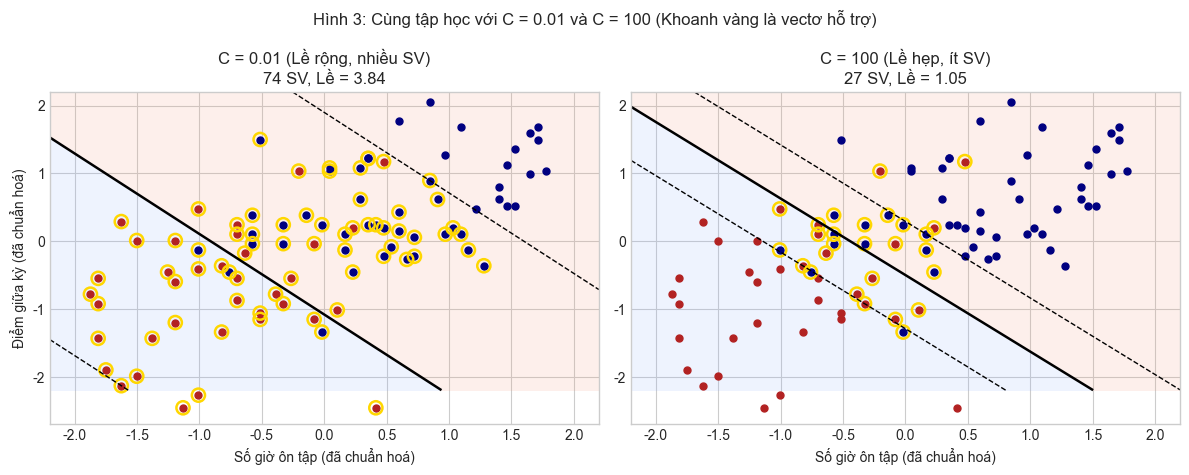

In [3]:
# Bước 2: Khảo sát lề mềm, tham số C và tầm quan trọng của chuẩn hóa

# 1. Đọc dữ liệu sinh viên
df_sv = pd.read_csv(path_sv)
X_sv = df_sv[["gio_on", "diem_giua_ky"]]
y_sv = df_sv["qua_mon"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X_sv, y_sv, test_size=0.25, random_state=17, stratify=y_sv
)

print("Tap hoc co", len(X_tr), "ban")
print("     C   so vecto HT   do rong le   tap hoc   tap kiem tra")
for C in [0.01, 0.1, 1, 10, 100]:
    mh = make_pipeline(StandardScaler(), SVC(kernel="linear", C=C))
    mh.fit(X_tr, y_tr)
    svm_soft = mh[-1]
    le = 2 / np.linalg.norm(svm_soft.coef_[0])
    a_hoc = accuracy_score(y_tr, mh.predict(X_tr))
    a_kt = accuracy_score(y_te, mh.predict(X_te))
    print(f" {C:6}       {len(svm_soft.support_):2d}        {le:6.2f}     {a_hoc:.4f}       {a_kt:.4f}")
print()

# 2. Vẽ so sánh hai mức C = 0.01 và C = 100 (Hình 3 trong PDF)
scaler = StandardScaler().fit(X_tr)
X_tr_sc = scaler.transform(X_tr)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, C_val, title in [(ax1, 0.01, 'C = 0.01 (Lề rộng, nhiều SV)'), (ax2, 100, 'C = 100 (Lề hẹp, ít SV)')]:
    m = SVC(kernel="linear", C=C_val).fit(X_tr_sc, y_tr)
    # Lưới toạ độ
    x_s = np.linspace(-2.2, 2.2, 300)
    y_s = np.linspace(-2.2, 2.2, 300)
    xx, yy = np.meshgrid(x_s, y_s)
    Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap=plt.cm.coolwarm)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors=['black', 'black', 'black'], linewidths=[1, 1.8, 1])
    ax.scatter(X_tr_sc[y_tr == 1, 0], X_tr_sc[y_tr == 1, 1], color='navy', s=25, label='Qua môn')
    ax.scatter(X_tr_sc[y_tr == 0, 0], X_tr_sc[y_tr == 0, 1], color='firebrick', s=25, label='Rớt môn')
    # Khoanh vàng vectơ hỗ trợ
    sv = X_tr_sc[m.support_]
    ax.scatter(sv[:, 0], sv[:, 1], s=90, facecolors='none', edgecolors='gold', linewidths=1.8)
    ax.set_title(f"{title}\n{len(m.support_)} SV, Lề = {2/np.linalg.norm(m.coef_[0]):.2f}")
    ax.set_xlabel("Số giờ ôn tập (đã chuẩn hoá)")
    ax.set_ylabel("Điểm giữa kỳ (đã chuẩn hoá)" if ax == ax1 else "")

plt.suptitle("Hình 3: Cùng tập học với C = 0.01 và C = 100 (Khoanh vàng là vectơ hỗ trợ)")
plt.tight_layout()
plt.show()

# 3. Kiểm chứng SVM bắt buộc phải chuẩn hoá trên bộ sinh viên mở rộng
df_mr = pd.read_csv(path_sv_mr)
X3 = df_mr[["gio_on", "diem_giua_ky", "chi_tieu"]]
y3 = df_mr["qua_mon"]
X3_tr, X3_te, y3_tr, y3_te = train_test_split(
    X3, y3, test_size=0.25, random_state=17, stratify=y3
)

tho = SVC().fit(X3_tr, y3_tr)
chuan = make_pipeline(StandardScaler(), SVC()).fit(X3_tr, y3_tr)

print("Ba cot (co chi_tieu tinh bang nghin dong), kernel RBF mac dinh:")
print(f" Doan bua ca lop qua : {y3_te.mean():.4f}")
print(f" Khong chuan hoa     : {accuracy_score(y3_te, tho.predict(X3_te)):.4f}")
print(f" Co chuan hoa        : {accuracy_score(y3_te, chuan.predict(X3_te)):.4f}")


---
## 3. KERNEL VÀ BIÊN CONG (g3_kernel.py)

### 3.1. Ý tưởng nâng chiều không gian (Feature Mapping)
Dữ liệu không thể phân tách tuyến tính ở số chiều hiện tại có thể phân tách được nếu ta ánh xạ sang không gian nhiều chiều hơn.
- Xét 14 điểm trên trục số 1 chiều: lớp 1 ở giữa, lớp 0 ở hai đầu $\rightarrow$ không có 1 ngưỡng nào cắt được (tối đa đúng $0.7143$).
- Khi thêm đặc trưng phi tuyến $x^2$: biến thành không gian 2D $(x, x^2)$, lớp 1 có $x^2$ nhỏ (nằm thấp) còn lớp 0 có $x^2$ lớn (nằm cao) $\rightarrow$ chỉ cần một đường thẳng nằm ngang là tách sạch $100\%$.

### 3.2. Thủ thuật Kernel (Kernel Trick)
Trong không gian nhiều chiều, số lượng đặc trưng tính toán sẽ bùng nổ theo cấp số nhân. May mắn là SVM không cần tính toạ độ thực của điểm trong không gian mới, mà chỉ cần biết **tích vô hướng/độ tương đồng** giữa 2 điểm:
$$K(x, z) = \langle \phi(x), \phi(z) \rangle$$

**Kernel RBF (Radial Basis Function):**
$$K(x, z) = e^{-\gamma \|x - z\|^2}$$
Hai điểm càng gần nhau thì $K \to 1$, càng xa nhau thì $K \to 0$.


Mot nguong tren truc x, tot nhat dung: 0.7143
Them cot x^2, SVM tuyen tinh dung : 1.0000

Hai vang trang, accuracy tren tap kiem tra:
  SVM kernel tuyen tinh        0.8667
  SVM kernel da thuc bac 3     0.8667
  SVM kernel RBF               0.9200
  Hoi quy logistic             0.8533
  KNN, k = 13                  0.9200

So vecto ho tro cua kernel RBF: 89 tren 225 diem hoc


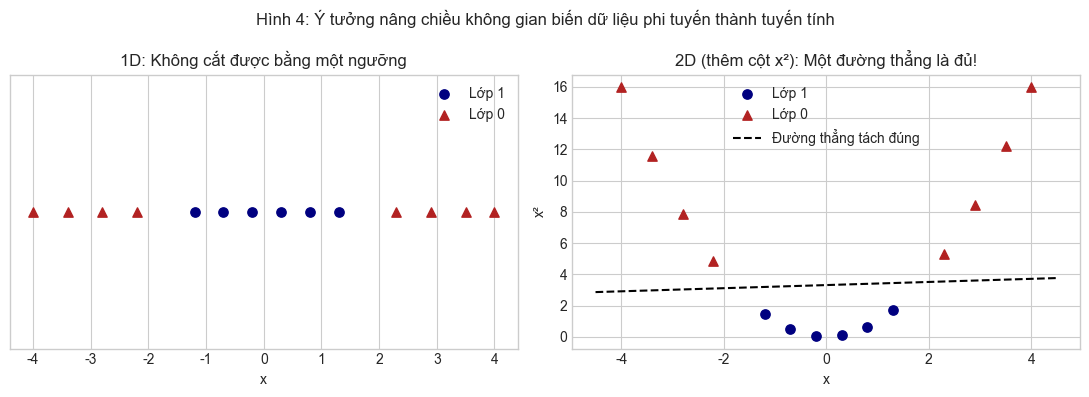

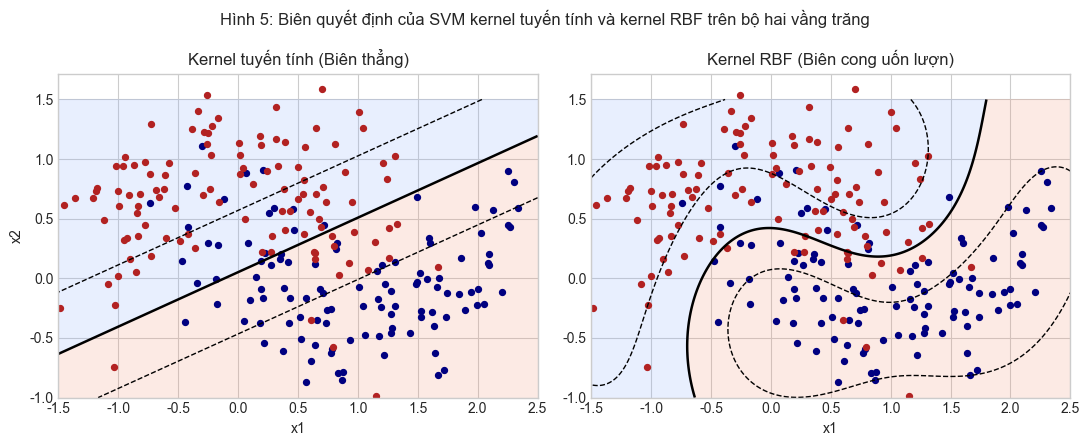

In [4]:
# Bước 3: Nâng chiều bằng tay và so sánh các loại kernel trên dữ liệu hai vầng trăng

# 1. Phần 1: Dữ liệu 1 chiều
x = np.array([-4.0, -3.4, -2.8, -2.2, -1.2, -0.7, -0.2, 0.3, 0.8, 1.3, 2.3, 2.9, 3.5, 4.0])
y_1d = (np.abs(x) < 1.8).astype(int)

tot = max(((x <= t).astype(int) == y_1d).mean() for t in x)
print(f"Mot nguong tren truc x, tot nhat dung: {tot:.4f}")

# Nâng chiều bằng tay: thêm cột x^2
X_moi = np.c_[x, x ** 2]
svm_nangchieu = SVC(kernel="linear", C=1000).fit(X_moi, y_1d)
print(f"Them cot x^2, SVM tuyen tinh dung : {svm_nangchieu.score(X_moi, y_1d):.4f}\n")

# Vẽ minh họa Hình 4 trong PDF
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(x[y_1d == 1], np.zeros((y_1d == 1).sum()), color='navy', marker='o', s=45, label='Lớp 1')
ax1.scatter(x[y_1d == 0], np.zeros((y_1d == 0).sum()), color='firebrick', marker='^', s=45, label='Lớp 0')
ax1.set_yticks([])
ax1.set_xlabel('x')
ax1.set_title('1D: Không cắt được bằng một ngưỡng')
ax1.legend()

ax2.scatter(x[y_1d == 1], (x[y_1d == 1])**2, color='navy', marker='o', s=45, label='Lớp 1')
ax2.scatter(x[y_1d == 0], (x[y_1d == 0])**2, color='firebrick', marker='^', s=45, label='Lớp 0')
# Đường phân cách ngang
w_nc = svm_nangchieu.coef_[0]
b_nc = svm_nangchieu.intercept_[0]
x_line = np.linspace(-4.5, 4.5, 100)
y_line = -(w_nc[0] * x_line + b_nc) / w_nc[1]
ax2.plot(x_line, y_line, 'k--', label='Đường thẳng tách đúng')
ax2.set_xlabel('x')
ax2.set_ylabel('x²')
ax2.set_title('2D (thêm cột x²): Một đường thẳng là đủ!')
ax2.legend()
plt.suptitle('Hình 4: Ý tưởng nâng chiều không gian biến dữ liệu phi tuyến thành tuyến tính')
plt.tight_layout()
plt.show()

# 2. Phần 2: Thử nghiệm trên bộ dữ liệu hai vầng trăng
df_moon = pd.read_csv(path_moon)
X_moon = df_moon[["x1", "x2"]]
y_moon = df_moon["nhan"]

X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(
    X_moon, y_moon, test_size=0.25, random_state=17, stratify=y_moon
)

mo_hinh = {
    "SVM kernel tuyen tinh"     : SVC(kernel="linear"),
    "SVM kernel da thuc bac 3"  : SVC(kernel="poly", degree=3),
    "SVM kernel RBF"            : SVC(kernel="rbf"),
    "Hoi quy logistic"          : LogisticRegression(),
    "KNN, k = 13"               : KNeighborsClassifier(n_neighbors=13),
}

print("Hai vang trang, accuracy tren tap kiem tra:")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr_m, y_tr_m)
    acc = accuracy_score(y_te_m, mh.predict(X_te_m))
    print(f"  {ten:28s} {acc:.4f}")

rbf = mo_hinh["SVM kernel RBF"]
print(f"\nSo vecto ho tro cua kernel RBF: {len(rbf.support_)} tren {len(X_tr_m)} diem hoc")

# Vẽ đường biên quyết định tuyến tính vs RBF (Hình 5 trong PDF)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
x_m = np.linspace(-1.5, 2.5, 300)
y_m = np.linspace(-1.0, 1.5, 300)
xx_m, yy_m = np.meshgrid(x_m, y_m)

for ax, model_name, title in [(ax1, "SVM kernel tuyen tinh", 'Kernel tuyến tính (Biên thẳng)'), 
                              (ax2, "SVM kernel RBF", 'Kernel RBF (Biên cong uốn lượn)')]:
    m = mo_hinh[model_name]
    Z = m.decision_function(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)
    ax.contourf(xx_m, yy_m, Z > 0, alpha=0.2, cmap=plt.cm.coolwarm)
    ax.contour(xx_m, yy_m, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors=['black', 'black', 'black'], linewidths=[1, 1.8, 1])
    ax.scatter(X_tr_m[y_tr_m == 1]["x1"], X_tr_m[y_tr_m == 1]["x2"], color='navy', s=18, label='Lớp 1')
    ax.scatter(X_tr_m[y_tr_m == 0]["x1"], X_tr_m[y_tr_m == 0]["x2"], color='firebrick', s=18, label='Lớp 0')
    ax.set_title(title)
    ax.set_xlabel("x1")
    ax.set_ylabel("x2" if ax == ax1 else "")

plt.suptitle("Hình 5: Biên quyết định của SVM kernel tuyến tính và kernel RBF trên bộ hai vầng trăng")
plt.tight_layout()
plt.show()


### 3.3. So sánh các mô hình
| Mô hình | Accuracy kiểm tra | Đặc điểm biên phân chia |
| :--- | :---: | :--- |
| **SVM kernel tuyến tính** | $0.8667$ | Đường thẳng, không uốn lượn theo vầng trăng |
| **Hồi quy Logistic** | $0.8533$ | Đường thẳng |
| **SVM kernel đa thức bậc 3** | $0.8667$ | Đường cong đa thức đơn giản |
| **KNN ($k=13$)** | $0.9200$ | Biên uốn lượn mềm mại, nhưng phải lưu cả 225 điểm |
| **SVM kernel RBF** | **$0.9200$** | Biên cong mượt mà chuẩn xác, **chỉ cần giữ 89 vectơ hỗ trợ**! |

**Ưu điểm của SVM so với KNN:** Khi dự đoán, SVM chỉ cần tính khoảng cách tới 89 vectơ hỗ trợ, trọng số của mỗi vectơ phụ thuộc vào độ tương đồng kernel RBF. KNN phải lưu toàn bộ 225 điểm và mọi láng giềng đều bỏ phiếu ngang nhau.


---
## 4. CHỌN THAM SỐ C VÀ GAMMA (g4_chon_tham_so.py)

Kernel RBF có 2 siêu tham số then chốt cần tinh chỉnh:
1. **$C$ (Cost):** Mức phạt điểm vi phạm. $C$ càng lớn lề càng hẹp, ranh giới càng cố ép đúng hết các điểm.
2. **$\gamma$ (Gamma):** Bán kính ảnh hưởng của mỗi vectơ hỗ trợ ($e^{-\gamma \|x-z\|^2}$):
   - **Gamma nhỏ ($\gamma = 0.1$):** Vùng ảnh hưởng lan rộng $\rightarrow$ ranh giới phẳng, mượt mà (dễ bị cẩu thả / underfitting).
   - **Gamma vừa ($\gamma = 1$):** Vùng ảnh hưởng vừa vặn $\rightarrow$ biên uốn lượn bám theo hình dạng dữ liệu.
   - **Gamma lớn ($\gamma = 100$):** Mỗi điểm chỉ ảnh hưởng một đốm nhỏ quanh nó $\rightarrow$ ranh giới vỡ vụn thành các hòn đảo nhỏ cô lập bao quanh từng điểm dữ liệu $\rightarrow$ **học vẹt / overfitting nghiêm trọng**!


Khảo sát gamma với C = 1:
gamma   tap hoc   tap kiem tra   so vecto HT
   0.1   0.8356       0.8533         113
     1   0.8711       0.9200         88
    10   0.8978       0.9067         128
   100   0.9422       0.8133         217

Diem kiem dinh cheo (hang la C, cot la gamma):
gamma   0.01    0.10    1.00    10.00
C                                    
0.1    0.6578  0.8044  0.8444  0.8578
1.0    0.8044  0.8178  0.8667  0.8667
10.0   0.8178  0.8400  0.8711  0.8311
100.0  0.8178  0.8533  0.8711  0.7467

Cap tot nhat: {'C': 10, 'gamma': 1}
Diem kiem dinh cheo: 0.8711
Accuracy tren tap kiem tra: 0.9200


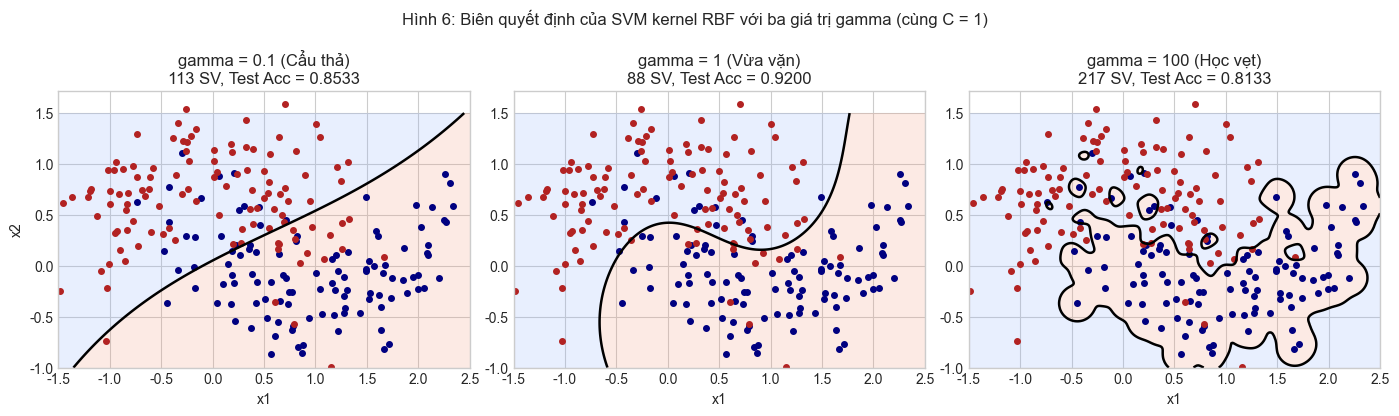

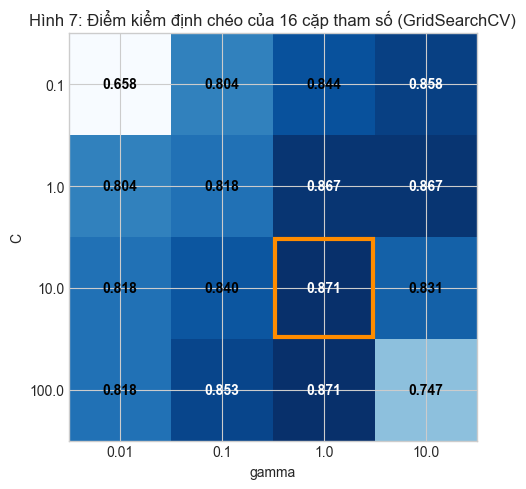

In [5]:
# Bước 4: Ảnh hưởng của gamma và dò lưới C, gamma bằng GridSearchCV

# 1. Khảo sát ảnh hưởng của gamma khi giữ cố định C = 1
print("Khảo sát gamma với C = 1:")
print("gamma   tap hoc   tap kiem tra   so vecto HT")
gamma_list = [0.1, 1, 10, 100]
for g in gamma_list:
    mh = SVC(kernel="rbf", gamma=g, C=1).fit(X_tr_m, y_tr_m)
    a_hoc = accuracy_score(y_tr_m, mh.predict(X_tr_m))
    a_kt = accuracy_score(y_te_m, mh.predict(X_te_m))
    print(f" {g:5}   {a_hoc:.4f}       {a_kt:.4f}         {len(mh.support_)}")
print()

# Vẽ minh họa Hình 6 trong PDF
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, g_val, title in zip(axes, [0.1, 1, 100], ['gamma = 0.1 (Cẩu thả)', 'gamma = 1 (Vừa vặn)', 'gamma = 100 (Học vẹt)']):
    m = SVC(kernel="rbf", gamma=g_val, C=1).fit(X_tr_m, y_tr_m)
    Z = m.decision_function(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)
    ax.contourf(xx_m, yy_m, Z > 0, alpha=0.2, cmap=plt.cm.coolwarm)
    ax.contour(xx_m, yy_m, Z, levels=[0], colors='black', linewidths=1.8)
    ax.scatter(X_tr_m[y_tr_m == 1]["x1"], X_tr_m[y_tr_m == 1]["x2"], color='navy', s=16)
    ax.scatter(X_tr_m[y_tr_m == 0]["x1"], X_tr_m[y_tr_m == 0]["x2"], color='firebrick', s=16)
    ax.set_title(f"{title}\n{len(m.support_)} SV, Test Acc = {accuracy_score(y_te_m, m.predict(X_te_m)):.4f}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2" if ax == axes[0] else "")

plt.suptitle("Hình 6: Biên quyết định của SVM kernel RBF với ba giá trị gamma (cùng C = 1)")
plt.tight_layout()
plt.show()

# 2. Dò lưới tìm cặp (C, gamma) tối ưu bằng kiểm định chéo 5-fold
luoi = {"C": [0.1, 1, 10, 100], "gamma": [0.01, 0.1, 1, 10]}
tim = GridSearchCV(SVC(kernel="rbf"), luoi, cv=5)
tim.fit(X_tr_m, y_tr_m)

bang = pd.DataFrame(tim.cv_results_["params"])
bang["diem"] = tim.cv_results_["mean_test_score"]
ma_tran_cv = bang.pivot(index="C", columns="gamma", values="diem")
print("Diem kiem dinh cheo (hang la C, cot la gamma):")
print(ma_tran_cv.round(4).to_string())
print()
print("Cap tot nhat:", tim.best_params_)
print(f"Diem kiem dinh cheo: {tim.best_score_:.4f}")
print(f"Accuracy tren tap kiem tra: {tim.score(X_te_m, y_te_m):.4f}")

# Vẽ Heatmap ma trận kiểm định chéo (Hình 7 trong PDF)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(ma_tran_cv.values, cmap="Blues", origin="upper")
ax.set_xticks(range(len(ma_tran_cv.columns)))
ax.set_yticks(range(len(ma_tran_cv.index)))
ax.set_xticklabels(ma_tran_cv.columns)
ax.set_yticklabels(ma_tran_cv.index)
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Hình 7: Điểm kiểm định chéo của 16 cặp tham số (GridSearchCV)")

for i in range(len(ma_tran_cv.index)):
    for j in range(len(ma_tran_cv.columns)):
        val = ma_tran_cv.values[i, j]
        color = "white" if val > 0.85 else "black"
        ax.text(j, i, f"{val:.3f}", ha="center", va="center", color=color, fontweight="bold")

# Đóng khung ô tốt nhất (C=10, gamma=1)
rect = plt.Rectangle((2 - 0.48, 2 - 0.48), 0.96, 0.96, fill=False, edgecolor='darkorange', lw=3)
ax.add_patch(rect)
plt.tight_layout()
plt.show()


---
## 5. NHẬN DẠNG CHỮ SỐ VIẾT TAY (g5_chu_so.py)

Bộ dữ liệu `load_digits` gồm 1797 ảnh chữ số viết tay kích thước $8 \times 8$ pixel:
- 64 đặc trưng (mỗi pixel là độ sáng từ 0 đến 16).
- 10 lớp tương ứng chữ số từ 0 đến 9.
- Bài toán đa lớp: `SVC` sử dụng cơ chế **One-vs-One (OvO)**, tự động tạo $\frac{10 \times 9}{2} = 45$ bộ phân loại nhị phân và cho chúng bỏ phiếu.


Kich thuoc X: (1797, 64)
Do sang nho nhat va lon nhat: 0.0 16.0
So anh moi chu so: [178 182 177 183 181 182 181 179 174 180]

SVM kernel RBF: accuracy 0.9911
So vecto ho tro: 626 tren 1347 anh
So anh doan sai: 4 tren 450
 anh   6: that la 9, doan la 3
 anh  18: that la 8, doan la 1
 anh 161: that la 4, doan la 8
 anh 428: that la 7, doan la 9

Cac mo hinh khac, accuracy tren tap kiem tra:
  SVM co chuan hoa         0.9778
  KNN, k = 5               0.9867
  Logistic co chuan hoa    0.9711


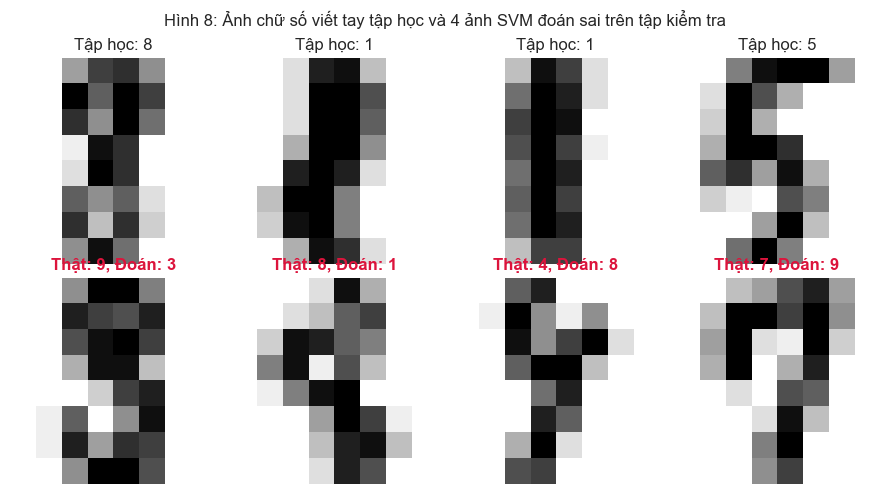

In [6]:
# Bước 5: Nhận dạng chữ số viết tay bằng SVM và so sánh các mô hình

X_dig, y_dig = load_digits(return_X_y=True)
print("Kich thuoc X:", X_dig.shape)
print("Do sang nho nhat va lon nhat:", X_dig.min(), X_dig.max())
print("So anh moi chu so:", np.bincount(y_dig))
print()

X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(
    X_dig, y_dig, test_size=0.25, random_state=17, stratify=y_dig
)

# 1. Huấn luyện SVM RBF mặc định
svm_digits = SVC(kernel="rbf").fit(X_tr_d, y_tr_d)
du_doan_d = svm_digits.predict(X_te_d)
acc_d = accuracy_score(y_te_d, du_doan_d)
print(f"SVM kernel RBF: accuracy {acc_d:.4f}")
print("So vecto ho tro:", len(svm_digits.support_), "tren", len(X_tr_d), "anh")

sai = np.flatnonzero(du_doan_d != y_te_d)
print("So anh doan sai:", len(sai), "tren", len(y_te_d))
for i in sai:
    print(f" anh {i:3d}: that la {y_te_d[i]}, doan la {du_doan_d[i]}")
print()

# 2. So với các mô hình khác
mo_hinh_digits = {
    "SVM co chuan hoa"     : make_pipeline(StandardScaler(), SVC()),
    "KNN, k = 5"           : KNeighborsClassifier(n_neighbors=5),
    "Logistic co chuan hoa": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}

print("Cac mo hinh khac, accuracy tren tap kiem tra:")
for ten, mh in mo_hinh_digits.items():
    mh.fit(X_tr_d, y_tr_d)
    acc = accuracy_score(y_te_d, mh.predict(X_te_d))
    print(f"  {ten:24s} {acc:.4f}")

# 3. Vẽ 8 ảnh đầu của tập học và 4 ảnh đoán sai (Hình 8 trong PDF)
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
# Hàng trên: 4 ảnh đầu của tập học
for j in range(4):
    ax = axes[0, j]
    ax.imshow(X_tr_d[j].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Tập học: {y_tr_d[j]}")
    ax.axis("off")

# Hàng dưới: 4 ảnh đoán sai trên tập test
for j, idx in enumerate(sai):
    ax = axes[1, j]
    ax.imshow(X_te_d[idx].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Thật: {y_te_d[idx]}, Đoán: {du_doan_d[idx]}", color="crimson", fontweight="bold")
    ax.axis("off")

plt.suptitle("Hình 8: Ảnh chữ số viết tay tập học và 4 ảnh SVM đoán sai trên tập kiểm tra")
plt.tight_layout()
plt.show()


---
## 6. BÀI TẬP 1: TÍNH TAY KHOẢNG CÁCH TỚI RANH GIỚI (Mục 7 - Bài tập 1)

### Yêu cầu:
1. Dùng $w_1, w_2, b$ in ra ở mục 2, tự tính $f(x)$ cho hai điểm $(3, 3)$ và $(5, 4.5)$ bằng phép nhân và cộng, không dùng `decision_function`.
2. Khoảng cách từ một điểm tới đường ranh giới bằng $d = \frac{|f(x)|}{\sqrt{w_1^2 + w_2^2}}$. Tính khoảng cách của hai điểm trên và của ba vectơ hỗ trợ.
3. **Vì sao khoảng cách của ba vectơ hỗ trợ bằng đúng một nửa độ rộng lề?**


In [7]:
# BÀI TẬP 1: Tính toán khoảng cách hình học tới ranh giới quyết định

w1_val = w[0]
w2_val = w[1]
b_val = b
norm_w = np.sqrt(w1_val ** 2 + w2_val ** 2)

# 1. Tự tính f(x) cho (3, 3) và (5, 4.5)
d1 = (3.0, 3.0)
d2 = (5.0, 4.5)

f_d1 = w1_val * d1[0] + w2_val * d1[1] + b_val
f_d2 = w1_val * d2[0] + w2_val * d2[1] + b_val

# 2. Tính khoảng cách tới ranh giới
dist_d1 = abs(f_d1) / norm_w
dist_d2 = abs(f_d2) / norm_w

print(f"Điểm (3, 3)    : f(x) = {f_d1:+.4f}, Khoảng cách d = {dist_d1:.4f}")
print(f"Điểm (5, 4.5)  : f(x) = {f_d2:+.4f}, Khoảng cách d = {dist_d2:.4f}")
print()

# 3. Tính khoảng cách của 3 vectơ hỗ trợ
print("Khoảng cách của 3 vectơ hỗ trợ tới ranh giới:")
for idx in svm.support_:
    pt = X[idx]
    f_sv = w1_val * pt[0] + w2_val * pt[1] + b_val
    dist_sv = abs(f_sv) / norm_w
    print(f"  Điểm {idx:2d} ({pt[0]:.2f}, {pt[1]:.2f}): |f(x)| = {abs(f_sv):.4f}, Khoảng cách d = {dist_sv:.4f}")

do_rong_le = 2 / norm_w
print(f"\nĐộ rộng của lề = 2 / ||w|| = {do_rong_le:.4f}")
print(f"Một nửa độ rộng lề = 1 / ||w|| = {do_rong_le / 2:.4f}")


Điểm (3, 3)    : f(x) = +1.2617, Khoảng cách d = 1.3958
Điểm (5, 4.5)  : f(x) = -0.9333, Khoảng cách d = 1.0325

Khoảng cách của 3 vectơ hỗ trợ tới ranh giới:
  Điểm 18 (5.20, 4.22): |f(x)| = 1.0001, Khoảng cách d = 1.1064
  Điểm 10 (2.88, 4.02): |f(x)| = 0.9999, Khoảng cách d = 1.1062
  Điểm 13 (3.59, 2.36): |f(x)| = 1.0002, Khoảng cách d = 1.1065

Độ rộng của lề = 2 / ||w|| = 2.2126
Một nửa độ rộng lề = 1 / ||w|| = 1.1063


---
## 7. BÀI TẬP 2: THÊM MỘT ĐIỂM (Mục 7 - Bài tập 2)

### Yêu cầu:
1. Thêm vào 24 điểm của mục 2 một điểm lớp 1 tại $(-1, -1)$, học lại và in $w_1, w_2, b$.
2. Sau đó bỏ điểm đó, thay bằng một điểm lớp 1 tại $(4.5, 4)$, học lại và in lần nữa.
3. **Lần nào đường ranh giới thay đổi? Giải thích bằng khái niệm vectơ hỗ trợ.**


Gốc       : w1 = -0.831, w2 = -0.355, b = 4.820
Thêm (-1,-1): w1 = -0.831, w2 = -0.355, b = 4.820
Thêm (4.5,4): w1 = -2.603, w2 = -0.807, b = 15.941


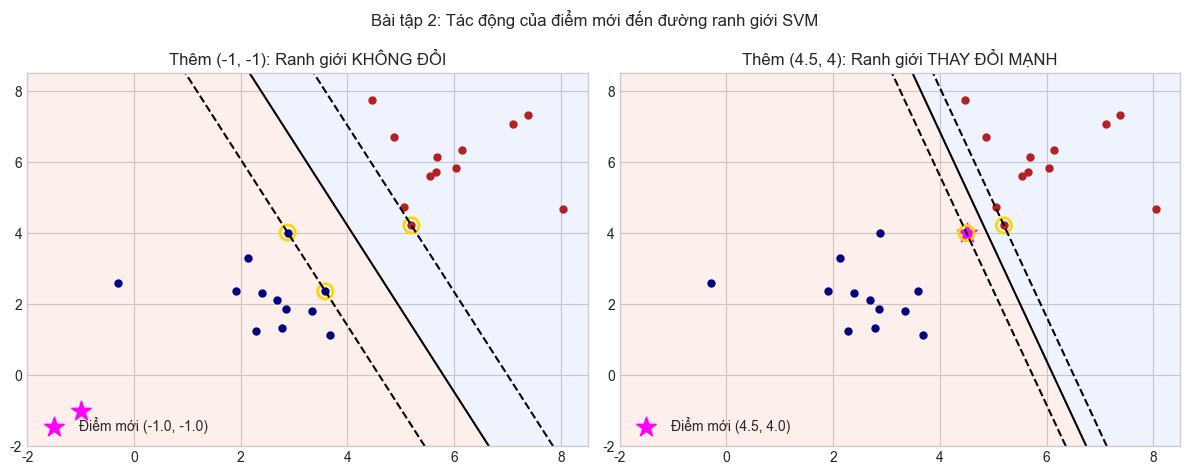

In [8]:
# BÀI TẬP 2: Khảo sát sự thay đổi của ranh giới khi thêm các điểm khác nhau

# Mô hình gốc trên 24 điểm
print(f"Gốc       : w1 = {w[0]:.3f}, w2 = {w[1]:.3f}, b = {b:.3f}")

# Lần 1: Thêm điểm (-1, -1) thuộc lớp 1
X_lan1 = np.vstack([X, [[-1.0, -1.0]]])
y_lan1 = np.append(y, 1)
svm_lan1 = SVC(kernel="linear", C=1000).fit(X_lan1, y_lan1)
w_l1 = svm_lan1.coef_[0]
b_l1 = svm_lan1.intercept_[0]
print(f"Thêm (-1,-1): w1 = {w_l1[0]:.3f}, w2 = {w_l1[1]:.3f}, b = {b_l1:.3f}")

# Lần 2: Thêm điểm (4.5, 4) thuộc lớp 1 (bỏ điểm (-1, -1))
X_lan2 = np.vstack([X, [[4.5, 4.0]]])
y_lan2 = np.append(y, 1)
svm_lan2 = SVC(kernel="linear", C=1000).fit(X_lan2, y_lan2)
w_l2 = svm_lan2.coef_[0]
b_l2 = svm_lan2.intercept_[0]
print(f"Thêm (4.5,4): w1 = {w_l2[0]:.3f}, w2 = {w_l2[1]:.3f}, b = {b_l2:.3f}")

# Trực quan hóa so sánh 2 trường hợp
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, X_cur, y_cur, svm_cur, pt_them, title in [
    (ax1, X_lan1, y_lan1, svm_lan1, (-1.0, -1.0), "Thêm (-1, -1): Ranh giới KHÔNG ĐỔI"),
    (ax2, X_lan2, y_lan2, svm_lan2, (4.5, 4.0), "Thêm (4.5, 4): Ranh giới THAY ĐỔI MẠNH")
]:
    x_s = np.linspace(-2, 8.5, 300)
    y_s = np.linspace(-2, 8.5, 300)
    xx, yy = np.meshgrid(x_s, y_s)
    Z = svm_cur.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap=plt.cm.coolwarm)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'], colors=['black', 'black', 'black'])
    ax.scatter(X_cur[y_cur == 1, 0], X_cur[y_cur == 1, 1], color='navy', s=25)
    ax.scatter(X_cur[y_cur == 0, 0], X_cur[y_cur == 0, 1], color='firebrick', s=25)
    # Điểm mới thêm
    ax.scatter([pt_them[0]], [pt_them[1]], color='magenta', marker='*', s=220, label=f'Điểm mới {pt_them}')
    # Vectơ hỗ trợ
    sv_c = X_cur[svm_cur.support_]
    ax.scatter(sv_c[:, 0], sv_c[:, 1], s=120, facecolors='none', edgecolors='gold', linewidths=2)
    ax.set_title(title)
    ax.legend(loc='lower left')

plt.suptitle("Bài tập 2: Tác động của điểm mới đến đường ranh giới SVM")
plt.tight_layout()
plt.show()


---
## 8. BÀI TẬP 3: KERNEL ĐA THỨC (Mục 7 - Bài tập 3)

### Yêu cầu:
1. Trên bộ hai vầng trăng, thử `SVC(kernel="poly", degree=d)` với $d \in [2, 3, 4]$, có chuẩn hoá bằng `make_pipeline`.
2. Với mỗi bậc, dò $C \in [0.1, 1, 10, 100]$ bằng `GridSearchCV` (tên tham số trong lưới là `"svc__C"`).
3. **Bậc nào tốt nhất? Có vượt được kernel RBF ở mục 5 không?**


In [9]:
# BÀI TẬP 3: Thử nghiệm kernel đa thức các bậc 2, 3, 4 trên hai vầng trăng

bac_list = [2, 3, 4]
ket_qua_poly = []

print("Khảo sát kernel đa thức (Polynomial Kernel):")
for d in bac_list:
    pipe = make_pipeline(StandardScaler(), SVC(kernel="poly", degree=d))
    luoi_poly = {"svc__C": [0.1, 1, 10, 100]}
    tim_poly = GridSearchCV(pipe, luoi_poly, cv=5)
    tim_poly.fit(X_tr_m, y_tr_m)
    
    c_tot = tim_poly.best_params_["svc__C"]
    cv_tot = tim_poly.best_score_
    test_acc = accuracy_score(y_te_m, tim_poly.predict(X_te_m))
    
    ket_qua_poly.append({
        "Bậc (degree)": d,
        "C tốt nhất": c_tot,
        "Điểm CV": cv_tot,
        "Accuracy test": test_acc
    })
    print(f"  Bậc {d}: C tốt nhất = {c_tot:3d}, Điểm CV = {cv_tot:.4f}, Accuracy test = {test_acc:.4f}")

df_poly = pd.DataFrame(ket_qua_poly)
print("\nSo sánh với Kernel RBF mục 5: CV = 0.8711, Accuracy test = 0.9200")


Khảo sát kernel đa thức (Polynomial Kernel):
  Bậc 2: C tốt nhất =   1, Điểm CV = 0.5422, Accuracy test = 0.5067
  Bậc 3: C tốt nhất =   1, Điểm CV = 0.8178, Accuracy test = 0.8267
  Bậc 4: C tốt nhất = 100, Điểm CV = 0.5156, Accuracy test = 0.4800

So sánh với Kernel RBF mục 5: CV = 0.8711, Accuracy test = 0.9200


---
## 9. BÀI TẬP 4: DÒ LƯỚI MỊN (Mục 7 - Bài tập 4)

### Yêu cầu:
1. Quanh cặp tốt nhất của mục 5 ($C=10, \gamma=1$), dò lại với $C \in [3, 10, 30]$ và $\gamma \in [0.3, 1, 3]$.
2. Điểm kiểm định chéo tốt nhất có cao hơn $0.8711$ không?
3. Accuracy trên tập kiểm tra có đổi không?
4. **Nhận xét về cái lợi của việc dò thật mịn.**


In [10]:
# BÀI TẬP 4: Dò lưới mịn xung quanh vùng tối ưu (C=10, gamma=1)

luoi_min = {
    "C": [3, 10, 30],
    "gamma": [0.3, 1, 3]
}

tim_min = GridSearchCV(SVC(kernel="rbf"), luoi_min, cv=5)
tim_min.fit(X_tr_m, y_tr_m)

bang_min = pd.DataFrame(tim_min.cv_results_["params"])
bang_min["diem"] = tim_min.cv_results_["mean_test_score"]
ma_tran_min = bang_min.pivot(index="C", columns="gamma", values="diem")

print("Điểm kiểm định chéo khi dò lưới mịn (5-fold CV):")
print(ma_tran_min.round(4).to_string())
print()
print(f"Cặp tham số tốt nhất  : {tim_min.best_params_}")
print(f"Điểm CV tốt nhất      : {tim_min.best_score_:.4f} (lưới thưa ở mục 5 là 0.8711)")
print(f"Accuracy tập kiểm tra : {tim_min.score(X_te_m, y_te_m):.4f} (lưới thưa ở mục 5 là 0.9200)")


Điểm kiểm định chéo khi dò lưới mịn (5-fold CV):
gamma     0.3     1.0     3.0
C                            
3      0.8533  0.8711  0.8667
10     0.8489  0.8711  0.8667
30     0.8622  0.8756  0.8533

Cặp tham số tốt nhất  : {'C': 30, 'gamma': 1}
Điểm CV tốt nhất      : 0.8756 (lưới thưa ở mục 5 là 0.8711)
Accuracy tập kiểm tra : 0.9200 (lưới thưa ở mục 5 là 0.9200)


---
## 10. BÀI TẬP 5: CHỮ SỐ VIẾT TAY, NHỮNG LỖI HAY GẶP (Mục 7 - Bài tập 5)

### Yêu cầu:
1. Dùng `confusion_matrix` trong `sklearn.metrics` để in bảng nhầm lẫn $10 \times 10$ của SVM ở mục 6.
2. Đọc bảng và cho biết những cặp chữ số nào bị nhầm.
3. Dùng `plt.imshow(X_te[i].reshape(8, 8), cmap="gray_r")` để vẽ và lưu từng ảnh bị đoán sai.
4. **Nhận xét vì sao SVM nhầm lẫn.**


MA TRẬN NHẦM LẪN (Hàng: Nhãn thật, Cột: Nhãn dự đoán):
[[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  0 44  0  0  0  0  0  0  0]
 [ 0  0  0 46  0  0  0  0  0  0]
 [ 0  0  0  0 44  0  0  0  1  0]
 [ 0  0  0  0  0 46  0  0  0  0]
 [ 0  0  0  0  0  0 45  0  0  0]
 [ 0  0  0  0  0  0  0 44  0  1]
 [ 0  1  0  0  0  0  0  0 42  0]
 [ 0  0  0  1  0  0  0  0  0 44]]

CÁC CẶP CHỮ SỐ BỊ NHẦM LẪN:
 - Thật là số 4 nhưng bị đoán nhầm thành số 8 (1 lần)
 - Thật là số 7 nhưng bị đoán nhầm thành số 9 (1 lần)
 - Thật là số 8 nhưng bị đoán nhầm thành số 1 (1 lần)
 - Thật là số 9 nhưng bị đoán nhầm thành số 3 (1 lần)

Đã lưu các ảnh bị đoán sai vào thư mục 'anh_doan_sai/'!


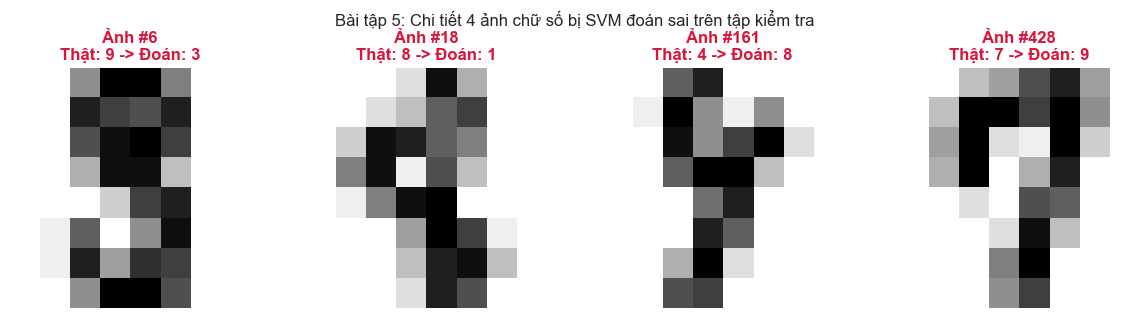

In [11]:
# BÀI TẬP 5: Phân tích ma trận nhầm lẫn và trực quan hóa các trường hợp sai

cm = confusion_matrix(y_te_d, du_doan_d)
print("MA TRẬN NHẦM LẪN (Hàng: Nhãn thật, Cột: Nhãn dự đoán):")
print(cm)
print()

# Tìm các cặp bị nhầm
print("CÁC CẶP CHỮ SỐ BỊ NHẦM LẪN:")
for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            print(f" - Thật là số {i} nhưng bị đoán nhầm thành số {j} ({cm[i, j]} lần)")
print()

# Vẽ và lưu từng ảnh bị đoán sai
os.makedirs("anh_doan_sai", exist_ok=True)
fig, axes = plt.subplots(1, len(sai), figsize=(12, 3.2))

for idx_sai, i in enumerate(sai):
    ax = axes[idx_sai]
    img = X_te_d[i].reshape(8, 8)
    ax.imshow(img, cmap="gray_r")
    tieu_de = f"Ảnh #{i}\nThật: {y_te_d[i]} -> Đoán: {du_doan_d[i]}"
    ax.set_title(tieu_de, color="crimson", fontweight="bold")
    ax.axis("off")
    
    # Lưu từng file ảnh riêng lẻ
    plt.imsave(f"anh_doan_sai/anh_{i}_that_{y_te_d[i]}_doan_{du_doan_d[i]}.png", img, cmap="gray_r")

plt.suptitle("Bài tập 5: Chi tiết 4 ảnh chữ số bị SVM đoán sai trên tập kiểm tra")
plt.tight_layout()
plt.show()
print("Đã lưu các ảnh bị đoán sai vào thư mục 'anh_doan_sai/'!")


---
## 11. BÀI TẬP 6: SVM TRÊN DỮ LIỆU LỚN (Mục 7 - Bài tập 6)

### Yêu cầu:
1. Tạo dữ liệu bằng `make_classification(n_samples=n, n_features=20, random_state=0)` với $n \in [2000, 5000, 10000, 20000]$.
2. Với mỗi kích cỡ, đo thời gian `.fit` của `SVC()` (kernel RBF) và của `LinearSVC()` bằng mô đun `time`.
3. **Lập bảng rồi nhận xét: khi dữ liệu tăng gấp đôi, thời gian học của mỗi mô hình tăng khoảng bao nhiêu lần?**


Đang đo thời gian huấn luyện trên các cỡ dữ liệu (vui lòng chờ)...
  n =  2000 -> SVC (RBF):  0.0434 s | LinearSVC:  0.0021 s
  n =  5000 -> SVC (RBF):  0.2087 s | LinearSVC:  0.0060 s
  n = 10000 -> SVC (RBF):  2.4645 s | LinearSVC:  0.0090 s
  n = 20000 -> SVC (RBF):  7.1621 s | LinearSVC:  0.0269 s

BẢNG TỔNG HỢP THỜI GIAN:
 Số mẫu (n)  Thời gian SVC (s)  Thời gian LinearSVC (s)
       2000             0.0434                   0.0021
       5000             0.2087                   0.0060
      10000             2.4645                   0.0090
      20000             7.1621                   0.0269


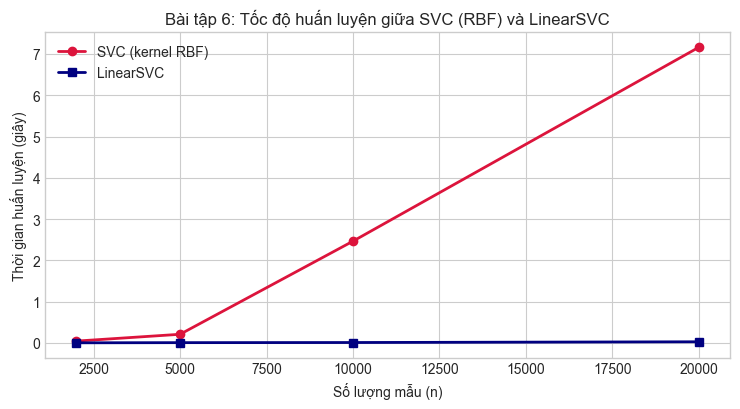

In [12]:
# BÀI TẬP 6: Đo thời gian huấn luyện của SVC (RBF) vs LinearSVC khi dữ liệu tăng dần

kich_co = [2000, 5000, 10000, 20000]
ket_qua_time = []

print("Đang đo thời gian huấn luyện trên các cỡ dữ liệu (vui lòng chờ)...")
for n in kich_co:
    X_big, y_big = make_classification(n_samples=n, n_features=20, random_state=0)
    
    # 1. Đo thời gian SVC (kernel RBF mặc định)
    t0 = time.time()
    SVC().fit(X_big, y_big)
    t_svc = time.time() - t0
    
    # 2. Đo thời gian LinearSVC
    t0 = time.time()
    LinearSVC(random_state=0, max_iter=2000).fit(X_big, y_big)
    t_lsvc = time.time() - t0
    
    ket_qua_time.append({
        "Số mẫu (n)": n,
        "Thời gian SVC (s)": round(t_svc, 4),
        "Thời gian LinearSVC (s)": round(t_lsvc, 4)
    })
    print(f"  n = {n:5d} -> SVC (RBF): {t_svc:7.4f} s | LinearSVC: {t_lsvc:7.4f} s")

df_time = pd.DataFrame(ket_qua_time)
print("\nBẢNG TỔNG HỢP THỜI GIAN:")
print(df_time.to_string(index=False))

# Vẽ biểu đồ so sánh thời gian chạy
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(df_time["Số mẫu (n)"], df_time["Thời gian SVC (s)"], 'o-', color='crimson', lw=2, label='SVC (kernel RBF)')
ax.plot(df_time["Số mẫu (n)"], df_time["Thời gian LinearSVC (s)"], 's-', color='navy', lw=2, label='LinearSVC')
ax.set_xlabel("Số lượng mẫu (n)")
ax.set_ylabel("Thời gian huấn luyện (giây)")
ax.set_title("Bài tập 6: Tốc độ huấn luyện giữa SVC (RBF) và LinearSVC")
ax.legend()
plt.tight_layout()
plt.show()
